# Milestone 3 — Notebook 1: Model training


## 1. Connect to Google Cloud Storage
Use the default CPU runtime in Colab.

In [1]:
# Settings: the existing Milestone 2 files in GCS.
DATA_MODE = "gcs"
BUCKET_NAME = "conor-weekes-data-20084449"
FOLDER = f"gs://{BUCKET_NAME}/milestone2/processed"
LOCAL_FOLDER = "/content"
RANDOM_SEED = 42

if DATA_MODE == "gcs":
    !pip -q install gcsfs
    from google.colab import auth
    auth.authenticate_user()
else:
    FOLDER = LOCAL_FOLDER

## 2. Load training and development data


In [2]:
import pandas as pd
import numpy as np

# Same processed CSV files you created in Milestone 2.
train = pd.read_csv(f"{FOLDER}/train_processed.csv")
dev = pd.read_csv(f"{FOLDER}/dev_processed.csv")
test = pd.read_csv(f"{FOLDER}/test_processed.csv")

features = ["fund_return_2017", "fund_return_2018", "fund_return_2019"]
target = "fund_return_2021_q1"

X_train = train[features].to_numpy(dtype="float32")
y_train = train[target].to_numpy(dtype="float32")
X_dev = dev[features].to_numpy(dtype="float32")
y_dev = dev[target].to_numpy(dtype="float32")

print("Training:", train.shape)
print("Development:", dev.shape)
print("Test:", test.shape)

assert not train[features + [target]].isna().any().any()
assert not dev[features + [target]].isna().any().any()

Training: (18107, 5)
Development: (2265, 5)
Test: (2256, 5)


## 3. Compare a baseline with DummyRegressor model

In [3]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
import time

results = []

model = DummyRegressor(strategy="mean")

start = time.time()
model.fit(X_train, y_train)
seconds = time.time() - start

predictions = model.predict(X_dev)

mae = mean_absolute_error(y_dev, predictions)
rmse = np.sqrt(mean_squared_error(y_dev, predictions))
r2 = r2_score(y_dev, predictions)

results.append({
    "Model": "Dummy baseline",
    "Training seconds": seconds,
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
})

print("Dummy baseline MAE:", round(mae * 100, 3), "percentage points")

results_df = pd.DataFrame(results)
display(results_df)


Dummy baseline MAE: 4.379 percentage points


,Model,Training seconds,MAE,RMSE,R2
0,Dummy baseline,0.001129,0.043785,0.058758,-0.000326


## 4. Train a PyTorch neural network


In [4]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

HIDDEN_SIZE = 16
EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 0.003
DEVICE = "cpu"

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Regression network:
class FundMLP(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, 1),
        )

    def forward(self, x):
        return self.network(x)

model = FundMLP(HIDDEN_SIZE).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.MSELoss()

xtr = torch.tensor(X_train)
ytr = torch.tensor(y_train).reshape(-1, 1)
xdev = torch.tensor(X_dev)
ydev = torch.tensor(y_dev).reshape(-1, 1)
loader = DataLoader(TensorDataset(xtr, ytr), batch_size=BATCH_SIZE, shuffle=True)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

loss_history = []
start = time.time()

for epoch in range(EPOCHS):
    model.train()

    for batch_x, batch_y in loader:
        optimizer.zero_grad()
        prediction = model(batch_x)
        loss = loss_fn(prediction, batch_y)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        train_loss = loss_fn(model(xtr), ytr).item()
        dev_loss = loss_fn(model(xdev), ydev).item()

    loss_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "dev_loss": dev_loss
    })

with torch.no_grad():
    predictions = model(xdev).numpy().flatten()

seconds = time.time() - start

mae = mean_absolute_error(y_dev, predictions)
rmse = np.sqrt(mean_squared_error(y_dev, predictions))
r2 = r2_score(y_dev, predictions)

results_df.loc[len(results_df)] = [
    "PyTorch neural network",
    seconds,
    mae,
    rmse,
    r2
]

print("Neural network MAE:", round(mae * 100, 3), "percentage points")


Neural network MAE: 2.545 percentage points


## 5. Plotting the loss curve


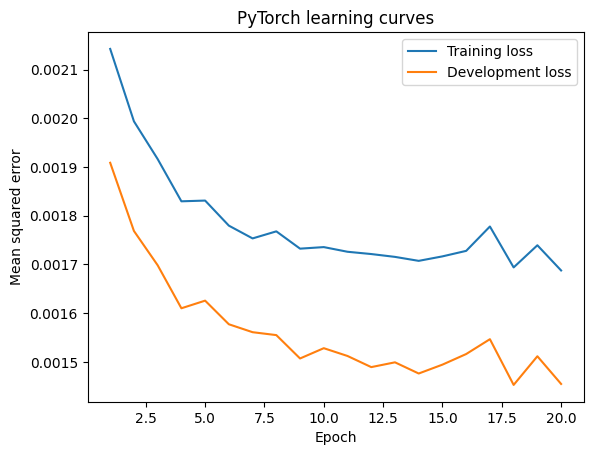

In [ ]:
loss_df = pd.DataFrame(loss_history)
plt.plot(loss_df["epoch"], loss_df["train_loss"], label="Training loss")
plt.plot(loss_df["epoch"], loss_df["dev_loss"], label="Development loss")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.title("PyTorch learning curves")
plt.legend()
plt.show()

## 6. Save results
Notebook 2 will perform a hyperparameter search with MLflow.

In [ ]:
from pathlib import Path
results_folder = Path("/content/m3_results" if Path("/content").exists() else "m3_results")
results_folder.mkdir(exist_ok=True)
results_df.to_csv(results_folder / "lab7_model_results.csv", index=False)
loss_df.to_csv(results_folder / "lab7_learning_curve.csv", index=False)
print("Saved results in", results_folder)

Saved results in /content/m3_results
